In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl



# 1. 폰트 설정 (Mac에서는 AppleGothic 사용)
mpl.rcParams['font.family'] = 'AppleGothic'
# 2. 마이너스(-) 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

In [17]:
# code 9-1 판다스 광고 클릭 테이블 가져오기
df = pd.read_csv('colored_ad_click_table.csv', encoding='CP949', low_memory=False)
df_col, df_row = df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 41 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Color                30 non-null     object
 1   Click Count: Day 1   30 non-null     int64 
 2   View Count: Day 1    30 non-null     int64 
 3   Click Count: Day 2   30 non-null     int64 
 4   View Count: Day 2    30 non-null     int64 
 5   Click Count: Day 3   30 non-null     int64 
 6   View Count: Day 3    30 non-null     int64 
 7   Click Count: Day 4   30 non-null     int64 
 8   View Count: Day 4    30 non-null     int64 
 9   Click Count: Day 5   30 non-null     int64 
 10  View Count: Day 5    30 non-null     int64 
 11  Click Count: Day 6   30 non-null     int64 
 12  View Count: Day 6    30 non-null     int64 
 13  Click Count: Day 7   30 non-null     int64 
 14  View Count: Day 7    30 non-null     int64 
 15  Click Count: Day 8   30 non-null     int64 
 16  View Count

In [7]:
# code 9-2 컬럼명 가지고 오기
df.Color.value_counts()

Color
Pink           1
Gray           1
Bronze         1
Silver         1
Magenta        1
Aquamarine     1
Green          1
Violet         1
Virdian        1
Yellow         1
Ultramarine    1
Jade           1
Gold           1
Indigo         1
Turquoise      1
Brown          1
Blue           1
Red            1
Tan            1
Black          1
Orange         1
Cyan           1
Teal           1
Maroon         1
Navy           1
Olive          1
Coral          1
Purple         1
Sapphire       1
Lime           1
Name: count, dtype: int64

In [8]:
# code 9-3 색상 이름 확인하기
print(df.Color.unique())
print(df['Color'].values) # book 내욘

['Pink' 'Gray' 'Sapphire' 'Purple' 'Coral' 'Olive' 'Navy' 'Maroon' 'Teal'
 'Cyan' 'Orange' 'Black' 'Tan' 'Red' 'Blue' 'Brown' 'Turquoise' 'Indigo'
 'Gold' 'Jade' 'Ultramarine' 'Yellow' 'Virdian' 'Violet' 'Green'
 'Aquamarine' 'Magenta' 'Silver' 'Bronze' 'Lime']
['Pink' 'Gray' 'Sapphire' 'Purple' 'Coral' 'Olive' 'Navy' 'Maroon' 'Teal'
 'Cyan' 'Orange' 'Black' 'Tan' 'Red' 'Blue' 'Brown' 'Turquoise' 'Indigo'
 'Gold' 'Jade' 'Ultramarine' 'Yellow' 'Virdian' 'Violet' 'Green'
 'Aquamarine' 'Magenta' 'Silver' 'Bronze' 'Lime']


In [9]:
# code 9-4 파란색 확인하기
assert 'Blue' in df['Color'].values

In [11]:
# code 9-5 실험 1일 차 요약하기
selected_columns = ['Color', 'Click Count: Day 1', 'View Count: Day 1']
df[selected_columns].describe()

,Click Count: Day 1,View Count: Day 1
count,30.000000,30.0
mean,23.533333,100.0
std,7.454382,0.0
min,12.000000,100.0
25%,19.250000,100.0
50%,24.000000,100.0
75%,26.750000,100.0
max,49.000000,100.0


In [18]:
# code 9-6 균일한 일일 조회 수 확인하기
view_columns = [column for column in df.columns if 'View' in column]
assert np.all(df[view_columns].values == 100)
print(view_columns)

['View Count: Day 1', 'View Count: Day 2', 'View Count: Day 3', 'View Count: Day 4', 'View Count: Day 5', 'View Count: Day 6', 'View Count: Day 7', 'View Count: Day 8', 'View Count: Day 9', 'View Count: Day 10', 'View Count: Day 11', 'View Count: Day 12', 'View Count: Day 13', 'View Count: Day 14', 'View Count: Day 15', 'View Count: Day 16', 'View Count: Day 17', 'View Count: Day 18', 'View Count: Day 19', 'View Count: Day 20']


In [19]:
# code 9-7 테이블에서 조회 수에 대한 열들 제거하기
df.drop(columns = view_columns, inplace = True)
print(df.columns)

Index(['Color', 'Click Count: Day 1', 'Click Count: Day 2',
       'Click Count: Day 3', 'Click Count: Day 4', 'Click Count: Day 5',
       'Click Count: Day 6', 'Click Count: Day 7', 'Click Count: Day 8',
       'Click Count: Day 9', 'Click Count: Day 10', 'Click Count: Day 11',
       'Click Count: Day 12', 'Click Count: Day 13', 'Click Count: Day 14',
       'Click Count: Day 15', 'Click Count: Day 16', 'Click Count: Day 17',
       'Click Count: Day 18', 'Click Count: Day 19', 'Click Count: Day 20'],
      dtype='object')


In [20]:
# code 9-8 일일 파란색 광고 클릭률에 대한 동계 정보 요약하기
df.set_index('Color', inplace=True)
print(df.T.Blue.describe())
print(df)

count    20.000000
mean     28.350000
std       5.499043
min      18.000000
25%      25.750000
50%      27.500000
75%      30.250000
max      42.000000
Name: Blue, dtype: float64
             Click Count: Day 1  Click Count: Day 2  Click Count: Day 3  \
Color                                                                     
Pink                         21                  20                  14   
Gray                         27                  27                  26   
Sapphire                     30                  32                  30   
Purple                       26                  21                  16   
Coral                        26                  24                  25   
Olive                        26                  19                  20   
Navy                         38                  29                  30   
Maroon                       21                  29                  24   
Teal                         25                  25                  32

In [21]:
df

,Click Count: Day 1,Click Count: Day 2,Click Count: Day 3,Click Count: Day 4,Click Count: Day 5,Click Count: Day 6,Click Count: Day 7,Click Count: Day 8,Click Count: Day 9,Click Count: Day 10,Click Count: Day 11,Click Count: Day 12,Click Count: Day 13,Click Count: Day 14,Click Count: Day 15,Click Count: Day 16,Click Count: Day 17,Click Count: Day 18,Click Count: Day 19,Click Count: Day 20
Color,,,,,,,,,,,,,,,,,,,,
Pink,21,20,14,30,12,23,26,21,16,21,21,16,30,24,17,23,15,22,19,20
Gray,27,27,26,17,29,27,19,21,28,24,23,21,18,18,18,25,21,27,25,24
Sapphire,30,32,30,26,32,29,21,26,28,27,33,22,27,29,38,33,30,30,30,25
Purple,26,21,16,17,23,17,21,30,15,26,17,20,24,19,24,22,20,26,25,33
Coral,26,24,25,27,36,30,36,31,31,26,37,25,21,23,20,26,21,22,26,25
Olive,26,19,20,23,27,11,24,18,22,29,26,24,15,17,10,16,21,23,26,26
Navy,38,29,30,32,29,22,29,30,25,23,26,30,27,23,29,37,30,25,31,41
Maroon,21,29,24,22,22,23,22,16,26,26,17,24,19,29,22,21,22,32,25,20
Teal,25,25,32,28,25,24,31,28,29,27,33,28,29,39,26,35,23,26,32,24


In [22]:
df.T

Color,Pink,Gray,Sapphire,Purple,Coral,Olive,Navy,Maroon,Teal,Cyan,...,Ultramarine,Yellow,Virdian,Violet,Green,Aquamarine,Magenta,Silver,Bronze,Lime
Click Count: Day 1,21,27,30,26,26,26,38,21,25,24,...,49,14,27,15,14,24,18,26,19,20
Click Count: Day 2,20,27,32,21,24,19,29,29,25,22,...,41,24,23,22,25,28,21,24,19,19
Click Count: Day 3,14,26,30,16,25,20,30,24,32,34,...,24,20,24,22,29,25,23,18,27,22
Click Count: Day 4,30,17,26,17,27,23,32,22,28,23,...,36,17,22,20,30,35,19,32,18,26
Click Count: Day 5,12,29,32,23,36,27,29,22,25,23,...,34,18,22,26,26,31,21,32,19,29
Click Count: Day 6,23,27,29,17,30,11,22,23,24,31,...,31,26,23,14,23,37,23,23,22,27
Click Count: Day 7,26,19,21,21,36,24,29,22,31,28,...,31,25,27,24,22,27,18,16,27,20
Click Count: Day 8,21,21,26,30,31,18,30,16,28,31,...,36,24,25,21,31,31,22,14,13,20
Click Count: Day 9,16,28,28,15,31,22,25,26,29,26,...,44,22,19,19,23,30,16,19,23,29
Click Count: Day 10,21,24,27,26,26,29,23,26,27,25,...,35,22,18,20,17,30,31,16,30,16


# 9.2 평균의 차이로 p-값 계산하기

In [23]:
# code 9-9 파란색이 없는 데이블 만들기
df_not_blue = df.T.drop(columns='Blue')
df_not_blue.head()

Color,Pink,Gray,Sapphire,Purple,Coral,Olive,Navy,Maroon,Teal,Cyan,...,Ultramarine,Yellow,Virdian,Violet,Green,Aquamarine,Magenta,Silver,Bronze,Lime
Click Count: Day 1,21,27,30,26,26,26,38,21,25,24,...,49,14,27,15,14,24,18,26,19,20
Click Count: Day 2,20,27,32,21,24,19,29,29,25,22,...,41,24,23,22,25,28,21,24,19,19
Click Count: Day 3,14,26,30,16,25,20,30,24,32,34,...,24,20,24,22,29,25,23,18,27,22
Click Count: Day 4,30,17,26,17,27,23,32,22,28,23,...,36,17,22,20,30,35,19,32,18,26
Click Count: Day 5,12,29,32,23,36,27,29,22,25,23,...,34,18,22,26,26,31,21,32,19,29


In [26]:
# code 9-10 순열 검정 함수 정의하기
def permutation_test(data_array_a, data_array_b):
    data_mean_a = data_array_a.mean()
    data_mean_b = data_array_b.mean()
    extreme_mean_diff = abs(data_mean_a - data_mean_b) # --- 관측된 표본 평균들 간 차이
    total_data = np.hstack([data_mean_a, data_mean_b])
    number_extreme_values = 0.0
    for _ in range(30000):
        np.random.shuffle(total_data)
        sample_a = total_data[:data_array_a.size]
        sample_b = total_data[data_array_a.size:]
        if abs(sample_a.mean() - sample_b.mean()) >= extreme_mean_diff: # --- 재 샘플링된 평균들 간 차이가 매우 큽니다
            number_extreme_values += 1

    p_value = number_extreme_values / 30000
    return p_value

/var/folders/72/kw4jxtc54k77pfy0tcqk7y1m0000gn/T/ipykernel_61277/3909853540.py:12: RuntimeWarning: Mean of empty slice.
  if abs(sample_a.mean() - sample_b.mean()) >= extreme_mean_diff: # --- 재 샘플링된 평균들 간 차이가 매우 큽니다
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


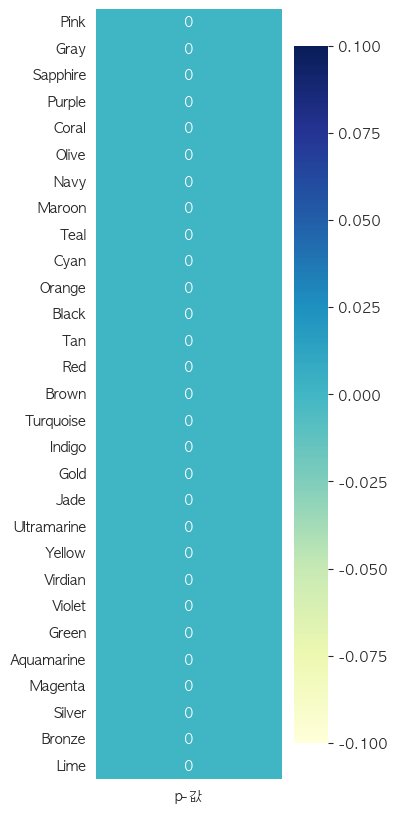

In [30]:
# code 9-11 색상들에 대한 순열 검정 실행하기
np.random.seed(0)
blue_clicks = df.T["Blue"].values
color_to_p_value = {}
for color, color_clicks in df_not_blue.items():
    p_value = permutation_test(blue_clicks, color_clicks)
    color_to_p_value[color] = p_value

sorted_colors, sorted_p_values = zip(*sorted(color_to_p_value.items(),
                                             key = lambda x : x[1]))
plt.figure(figsize=(3,10))
sns.heatmap([[p_value] for p_value in sorted_p_values],
            cmap = 'YlGnBu', annot = True, xticklabels =['p-값'],
            yticklabels=sorted_colors)
plt.show()